# SberQuAD: разведочный анализ

Чекпойнт 2 · Команда №14 · Куропатов Константин · Куратор Ляпин Данила

Проверим, как устроены вопросы, тексты и ответы, где есть ошибки разметки
и как разделить данные для дальнейших экспериментов.
Первый поисковый бейзлайн — TF-IDF; его реализация и оценка будут в чекпойнте 3.

In [1]:
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython import get_ipython
from IPython.display import Markdown, display

from rag_qa_eda import plots
from rag_qa_eda.data import load_sources
from rag_qa_eda.paths import PROCESSED, REPORTS, ROOT, TABLES

get_ipython().run_line_magic("matplotlib", "inline")

if not (PROCESSED / "qa_features.parquet").exists():
    raise FileNotFoundError("Сначала выполните из корня проекта: uv run rag-eda all")

qa = pd.read_parquet(PROCESSED / "qa_features.parquet")
corpus = pd.read_parquet(PROCESSED / "corpus_features.parquet")
labelled = qa.loc[qa.label_available].copy()
summary = json.loads((REPORTS / "summary.json").read_text())
plots.set_style()
pd.set_option("display.max_colwidth", 95)
pd.set_option("display.max_columns", 16)


def table(name):
    return pd.read_csv(TABLES / f"{name}.csv")


def show_plot(figure):
    display(figure)
    plt.close(figure)


print("Python:", sys.version.split()[0])
display(pd.Series(summary["environment"], name="Версия"))

Python: 3.12.12


python          3.12.12
pandas            2.3.3
numpy             2.5.4
scikit-learn      1.9.1
tokenizers       0.23.3
razdel            0.5.0
Name: Версия, dtype: object

## 1. Данные

[QA-версия SberQuAD](https://huggingface.co/datasets/kuznetsoffandrey/sberquad)
содержит вопросы, контексты и ответы.
[Retrieval-версия](https://huggingface.co/datasets/kaengreg/sberquad-retrieval)
и [qrels](https://huggingface.co/datasets/kaengreg/sberquad-retrieval-qrels)
связывают вопросы с документами корпуса. Версии закреплены в `config/data_sources.json`.

Один абзац может относиться к нескольким вопросам. Поэтому длины текстов
считаем по уникальным фрагментам, а вопросы и ответы — по строкам QA.

,path,revision,size_bytes,sha256
0,data/raw/qa/README.md,deb870ee29b2…,5159,85367f21fbdf93e6…
1,data/raw/qa/sberquad/train-00000-of-00001.parquet,deb870ee29b2…,11416696,9c0ec202bab5e3a0…
2,data/raw/qa/sberquad/validation-00000-of-00001.parquet,deb870ee29b2…,3425979,6a2617d1212cb32e…
3,data/raw/qa/sberquad/test-00000-of-00001.parquet,deb870ee29b2…,4927641,6e92c4d24f2fb2d7…
4,data/raw/retrieval/README.md,16f9539da18c…,170,9c0a8ed1cd8f7cf4…
5,data/raw/retrieval/corpus.jsonl,16f9539da18c…,45661956,d3b2a2a9d10767f8…
6,data/raw/retrieval/queries.jsonl,16f9539da18c…,22420917,d2dd4ae52d995e10…
7,data/raw/qrels/README.md,ceac8190a0bd…,228,328249af71db5a4e…
8,data/raw/qrels/train.tsv,ceac8190a0bd…,572256,57d50005351f1bb1…
9,data/raw/qrels/validation.tsv,ceac8190a0bd…,69197,cfa3082aeb7f21df…


,split,rows,unique_original_ids,contexts,labelled_rows,reader_eligible,median_question_words,median_context_words
0,train,45328,45328,9078,45328,36917,8.0,91.0
1,validation,5036,5036,3971,5036,4144,8.0,90.5
2,test,23936,23936,4425,0,0,8.0,90.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


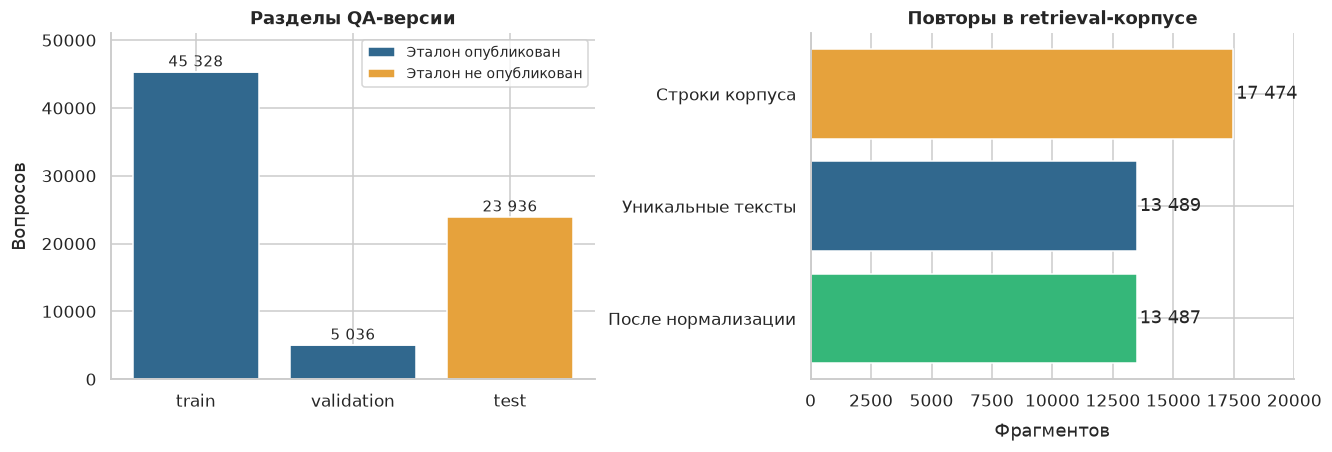

Всего **74,300 вопросов**, из них **50,364** с ответами. Строк в корпусе — 17,474; после удаления дублей остаётся **13,487 текстов**.

In [2]:
manifest = json.loads((REPORTS / "data_manifest.json").read_text())
manifest_df = pd.DataFrame(manifest["files"])
display(
    manifest_df.assign(
        revision=manifest_df.revision.str.slice(0, 12) + "…",
        sha256=manifest_df.sha256.str.slice(0, 16) + "…",
    )[["path", "revision", "size_bytes", "sha256"]]
)
display(table("source_overview"))
show_plot(plots.overview(summary))
audit = summary["join_audit"]
display(
    Markdown(
        f"Всего **{audit['queries']:,} вопросов**, из них **{summary['labelled_rows']:,}** "
        f"с ответами. Строк в корпусе — {audit['corpus_rows']:,}; после удаления "
        f"дублей остаётся **{audit['unique_normalized_contexts']:,} текстов**."
    )
)

## 2. Поля и основные статистики

Для QA эталон — текст ответа, для поиска — связь «вопрос → документ».
Все qrels положительные (`score=1`); готовых отрицательных примеров здесь нет.
В таблице `describe` словарь `answers` представлен строкой, чтобы pandas мог
посчитать частоты. В обработке данных текст и позиция ответа хранятся отдельно.

In [3]:
raw_qa, raw_corpus, raw_queries, raw_qrels = load_sources()
display(raw_qa[["id", "title", "context", "question", "answers", "split"]].head(3))
display(raw_qa.dtypes.astype(str).rename("dtype").to_frame())
display(
    raw_qa.drop(columns=["row_key", "source_row"])
    .assign(answers=raw_qa.answers.map(repr))
    .describe(include="all")
    .T
)
display(
    labelled[
        ["q_chars", "q_words", "c_chars", "c_words", "a_chars", "a_words", "a_position_relative"]
    ]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)
display(raw_qrels.score.value_counts(dropna=False).rename("Число qrels"))

,id,title,context,question,answers,split
0,62310,SberChallenge,"В протерозойских отложениях органические остатки встречаются намного чаще, чем в архейских....",чем представлены органические остатки?,"{'text': ['известковыми выделениями сине-зелёных водорослей'], 'answer_start': [109]}",train
1,28101,SberChallenge,"В протерозойских отложениях органические остатки встречаются намного чаще, чем в архейских....",что найдено в кремнистых сланцах железорудной формации Канады?,"{'text': ['нитевидные водоросли, грибные нити'], 'answer_start': [438]}",train
2,48834,SberChallenge,"В протерозойских отложениях органические остатки встречаются намного чаще, чем в архейских....",что встречается в протерозойских отложениях?,"{'text': ['органические остатки'], 'answer_start': [28]}",train


,dtype
id,int32
title,object
context,object
question,object
answers,object
split,object
source_row,int64
row_key,object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,74300.0,NaN,NaN,NaN,42220.34105,24369.972065,0.0,21117.75,42214.5,63296.25,84437.0
title,74300,1,SberChallenge,74300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
context,74300,13489,"Крылья, как правило, полностью покрыты чешуйками, которые представляют собой видоизменённые...",24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
question,74300,74284,Какой оттенок имеет понятие колония ?,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
answers,74300,49161,"{'text': array([''], dtype=object), 'answer_start': array([-1], dtype=int32)}",23936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
split,74300,3,train,45328,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
q_chars,50364.0,64.371654,32.212958,8.0,21.0,29.0,44.00000,58.000000,77.000000,121.00000,177.000000,670.000000
q_words,50364.0,8.629100,4.179029,2.0,3.0,4.0,6.00000,8.000000,10.000000,16.00000,23.000000,73.000000
c_chars,50364.0,753.855234,259.451275,279.0,501.0,512.0,578.00000,682.000000,859.000000,1208.00000,1590.000000,7231.000000
c_words,50364.0,99.927627,35.797279,39.0,58.0,64.0,76.00000,91.000000,115.000000,163.00000,214.370000,995.000000
a_chars,50364.0,26.102454,20.089905,1.0,3.0,6.0,12.00000,20.000000,35.000000,64.00000,94.000000,673.000000
a_words,50364.0,3.632734,2.504329,0.0,1.0,1.0,2.00000,3.000000,5.000000,8.00000,12.000000,108.000000
a_position_relative,41061.0,0.414243,0.295877,0.0,0.0,0.0,0.14927,0.374364,0.660819,0.92714,0.977591,0.997126


score
1    74300
Name: Число qrels, dtype: int64

`title` в QA — константа `SberChallenge`, а в корпусе заголовки пустые.
Название и URL статьи из этого поля не получить. ID используются как ключи.

## 3. Пропуски

Проверяем `null`, пустые строки и отрицательные позиции ответа.
Пустой ответ и неверная позиция при непустом ответе требуют разной обработки.

,source,split,field,rows,null_count,empty_string_count,missing_fraction
0,qa,train,id,45328,0,0,0.000000
1,qa,train,title,45328,0,0,0.000000
2,qa,train,context,45328,0,0,0.000000
3,qa,train,question,45328,0,0,0.000000
4,qa,train,answers,45328,0,0,0.000000
8,qa,validation,id,5036,0,0,0.000000
9,qa,validation,title,5036,0,0,0.000000
10,qa,validation,context,5036,0,0,0.000000
11,qa,validation,question,5036,0,0,0.000000
12,qa,validation,answers,5036,0,0,0.000000


,null_cells,total_cells,null_fraction,unpublished_answer_fraction
0,0,371500,0.0,0.322153


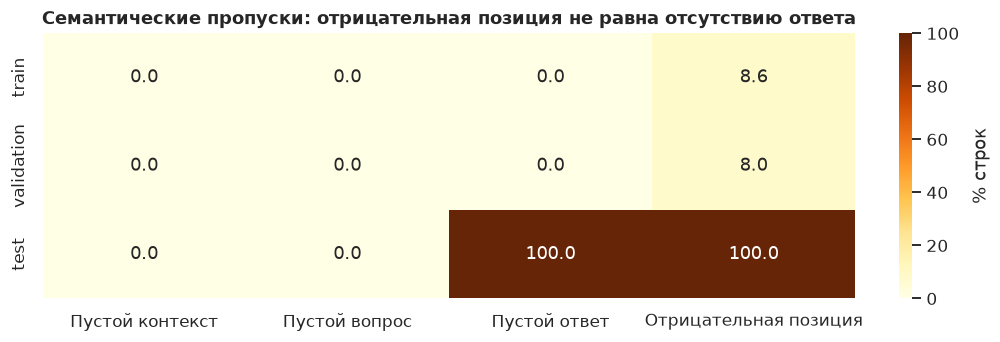

,row_key,question,answer_text,label_available
50364,test:0,У каких организмов отсутствуют настоящие дифференцированные клетки?,,False


У всех **23,936** вопросов исходного test ответ пустой, позиция — −1. Эталоны не опубликованы, поэтому эти строки отмечены `label_available=False`. Их нельзя использовать как вопросы без ответа. При этом в размеченных данных есть **4,288** отрицательных позиций — их проверяем по тексту. Пропуски не заполняем.

In [4]:
missing = table("missingness")
display(
    missing.loc[
        (missing.source.isin(["qa", "qa_nested"]))
        & missing.field.isin(
            [
                "id",
                "title",
                "context",
                "question",
                "answers",
                "answers.text (blank)",
                "answers.answer_start (negative)",
            ]
        )
    ]
)
fields = ["id", "title", "context", "question", "answers"]
display(
    pd.DataFrame(
        {
            "null_cells": [raw_qa[fields].isna().sum().sum()],
            "total_cells": [raw_qa[fields].size],
            "null_fraction": [raw_qa[fields].isna().to_numpy().mean()],
            "unpublished_answer_fraction": [(~qa.label_available).mean()],
        }
    )
)
show_plot(plots.missingness(qa))
display(
    qa.loc[
        qa.row_key.eq("test:0"),
        ["row_key", "question", "answer_text", "label_available"],
    ]
)
display(
    Markdown(
        f"У всех **{summary['unlabelled_rows']:,}** вопросов исходного test ответ пустой, "
        "позиция — −1. Эталоны не опубликованы, поэтому эти строки отмечены "
        "`label_available=False`. Их нельзя использовать как вопросы без ответа. "
        f"При этом в размеченных данных есть **{summary['raw_negative_offsets_labelled']:,}** "
        "отрицательных позиций — их проверяем по тексту. Пропуски не заполняем."
    )
)

## 4. Позиции ответов

По указанной позиции должна находиться ровно строка ответа. Если позиция
неверная, исправляем её только при единственном точном вхождении в контекст.
Дополнительно проверяем, что ответ не начинается и не заканчивается внутри слова.
Исходные текст и позиция сохраняются рядом с результатом проверки.

,split,span_status,rows,fraction_within_split
0,test,no_label,23936,1.000000
1,train,ambiguous_exact,153,0.003375
2,train,case_and_punctuation_mismatch,1718,0.037902
3,train,case_or_unicode_mismatch,5192,0.114543
4,train,exact,35091,0.774157
5,train,punctuation_or_space_mismatch,1140,0.025150
6,train,relocated_exact,2034,0.044873
7,validation,ambiguous_exact,9,0.001787
8,validation,case_and_punctuation_mismatch,180,0.035743
9,validation,case_or_unicode_mismatch,552,0.109611


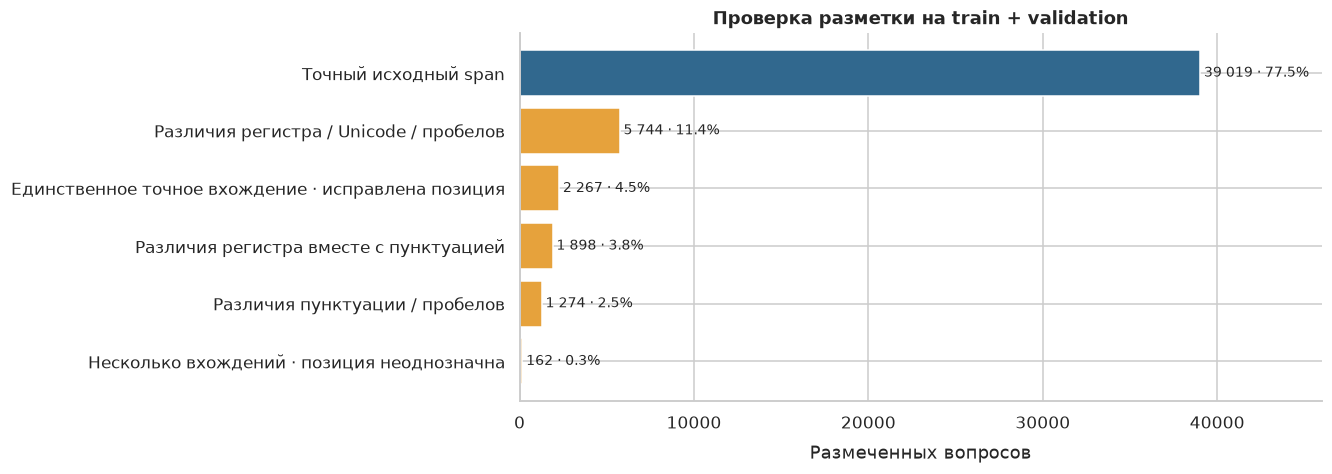

,row_key,question,answer_text,answer_start_raw,answer_start_fixed,word_boundary_ok
1,train:1,что найдено в кремнистых сланцах железорудной формации Канады?,"нитевидные водоросли, грибные нити",438,441,True
42,train:42,Чем связаны между собой листы макромолекул?,большим числом водородных связей,78,483,True
43,train:43,Одинаково ли ориентированы макромолекулы в микрофибрилле?,одинаково,698,935,True
58,train:58,Когда произошло видообразование путем скрещивания с образованием нового вида?,около 20 тысяч лет назад,419,559,True
79,train:79,Какой буквой традиционно обозначается скорость света в вакууме,латинской буквой c,436,130,True


Исходная позиция верна у **39,019** ответов; у **2,267** она восстановлена. Нарушения границ слова найдены в **225** случаях. Число строк для обучения извлечению ответа — **41,061** (`reader_eligible=True`). Для поиска документа позиция ответа не нужна.

In [5]:
display(table("span_status"))
show_plot(plots.spans(qa))
display(
    qa.loc[
        qa.span_status.eq("relocated_exact"),
        [
            "row_key",
            "question",
            "answer_text",
            "answer_start_raw",
            "answer_start_fixed",
            "word_boundary_ok",
        ],
    ].head(5)
)
display(
    Markdown(
        f"Исходная позиция верна у **{summary['raw_exact_spans']:,}** ответов; "
        f"у **{summary['unique_exact_relocations']:,}** она восстановлена. "
        f"Нарушения границ слова найдены в **{summary['span_boundary_violations']}** случаях. "
        f"Число строк для обучения извлечению ответа — **{summary['reader_eligible_rows']:,}** "
        "(`reader_eligible=True`). Для поиска документа позиция ответа не нужна."
    )
)

## 5. Примеры некачественных эталонов

При просмотре данных нашёл пару примеров некачественных эталонных ответов.

In [6]:
cases = pd.DataFrame(json.loads((ROOT / "config/illustrative_cases.json").read_text())["cases"])
case_data = cases.merge(
    qa[["row_key", "question", "answer_text"]],
    on="row_key",
    validate="one_to_one",
)
display(
    case_data.assign(answer_excerpt=case_data.answer_text.str.slice(0, 100))[
        ["row_key", "question", "answer_excerpt", "issue"]
    ]
)
for row in case_data.itertuples(index=False):
    display(Markdown(f"**{row.row_key}: {row.issue}.** {row.interpretation}"))

,row_key,question,answer_excerpt,issue
0,train:223,Что включает в себя эволюционная биология?,"на включает в себя как полевые, так и лабораторные направления различных наук",Оборванное начало эталона
1,train:43573,Сколько в первую неделю было продано копий альбома Issues группы Korn,Четвёртый альбом Issues (1999) группы Korn также попал на вершину Billboard 200.[118][153] ...,Почти весь контекст вместо числа


**train:223: Оборванное начало эталона.** Эталон начинается с «на включает…»: потеряна первая буква слова «она» из исходного текста. Сам текст ответа повреждён.

**train:43573: Почти весь контекст вместо числа.** Вопрос требует количества проданных копий; в контексте указано 573 000. Вместо краткого ответа в эталон попал почти весь абзац с посторонними сведениями.

Подробнее проверю разметку при анализе ошибок модели. В случаях, где ответ
модели сильно расходится с эталоном, буду сверять оба ответа с исходным
текстом: проблема может быть как в модели, так и в самом эталоне.

## 6. Длины и выбросы

Длины слов считаются регулярным выражением. Для длин контекстов берём один
текст на группу дублей. Логарифмическая шкала помогает увидеть длинный хвост.

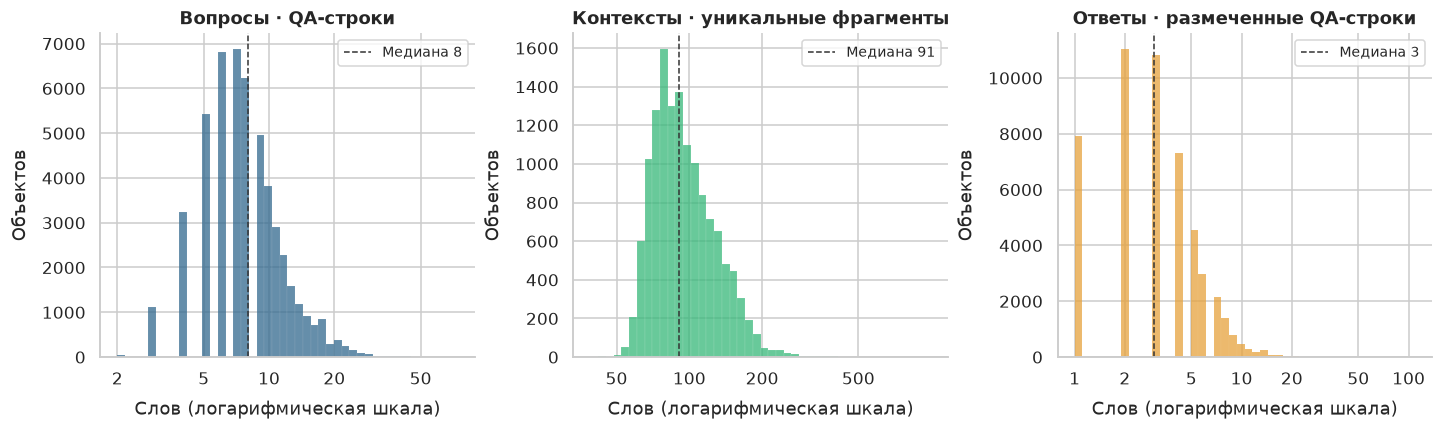

,feature,split,lower_train_iqr,upper_train_iqr,flagged,fraction,action
0,q_words,train,0.000000,16.000000,1984,0.043770,retain_and_flag
1,q_words,validation,0.000000,16.000000,233,0.046267,retain_and_flag
2,c_words,train,17.500000,173.500000,1480,0.032651,retain_and_flag
3,c_words,validation,17.500000,173.500000,173,0.034353,retain_and_flag
4,a_words,train,-2.500000,9.500000,1271,0.028040,retain_and_flag
5,a_words,validation,-2.500000,9.500000,144,0.028594,retain_and_flag
6,c_e5_tokens,train,34.000000,346.000000,1329,0.029320,retain_and_flag
7,c_e5_tokens,validation,34.000000,346.000000,164,0.032566,retain_and_flag
8,a_context_char_ratio,train,-0.034458,0.099916,2041,0.045027,retain_and_flag
9,a_context_char_ratio,validation,-0.034458,0.099916,232,0.046068,retain_and_flag


,row_key,question,a_words,span_status
0,train:43573,Сколько в первую неделю было продано копий альбома Issues группы Korn,108.0,punctuation_or_space_mismatch
1,train:36256,Как Лев Толстой описал постановление синода?,29.0,exact
2,train:26137,Почему во время Гражданской войны в США экспорт хлопка из страны почти прекратился?,28.0,case_or_unicode_mismatch
3,train:3405,"Что проявляется у большинства членистоногих, у ракообразных?",27.0,exact
4,train:23901,Какие районы Рязани подверглись озеленению?,26.0,exact
5,train:25439,К чему привёл предыдущий метод записи,26.0,exact
6,train:6252,Какие кассеты появились на потребительском рынке?,25.0,exact
7,train:14863,В каких банках есть доля компании?,25.0,exact


Медианный вопрос — **8 слов**, ответ — **3**. Для контекстов и ответов виден длинный хвост.

In [7]:
show_plot(plots.lengths(qa, corpus))
display(table("length_outliers"))
display(table("extreme_a_words")[["row_key", "question", "a_words", "span_status"]])
display(
    Markdown(
        f"Медианный вопрос — **{labelled.q_words.median():.0f} слов**, "
        f"ответ — **{labelled.a_words.median():.0f}**. "
        "Для контекстов и ответов виден длинный хвост."
    )
)

Пороги IQR рассчитаны на исходном train. Выбросы помечены, но сохранены:
длинный ответ может быть правильным. Случаи, где ответ занимает почти весь
абзац, стоит просмотреть перед обучением, а не обрезать автоматически.

## 7. Вопросы и ответы

Тип вопроса определяется по вопросительному слову среди первых трёх токенов;
вопросы с частицей «ли» выделены отдельно. В частотных списках показано число
объектов со словом. Лемматизации нет, поэтому формы одного слова считаются отдельно.

,question_type,rows,median_q_words,median_a_words,reader_eligible_fraction,median_lexical_coverage
0,какой,18990,8.0,3.0,0.834597,0.777778
1,что,11979,7.0,4.0,0.768512,0.800000
2,кто,4494,8.0,2.0,0.826213,0.750000
3,другое,3728,8.0,3.0,0.820815,0.750000
4,как,3589,7.0,2.0,0.843689,0.750000
5,когда,2506,7.0,4.0,0.852354,1.000000
6,сколько,2017,8.0,2.0,0.835399,0.833333
7,где,1787,6.0,3.0,0.775602,0.857143
8,ли / да-нет,435,8.0,3.0,0.772414,0.750000
9,куда,400,7.0,3.0,0.767500,0.833333


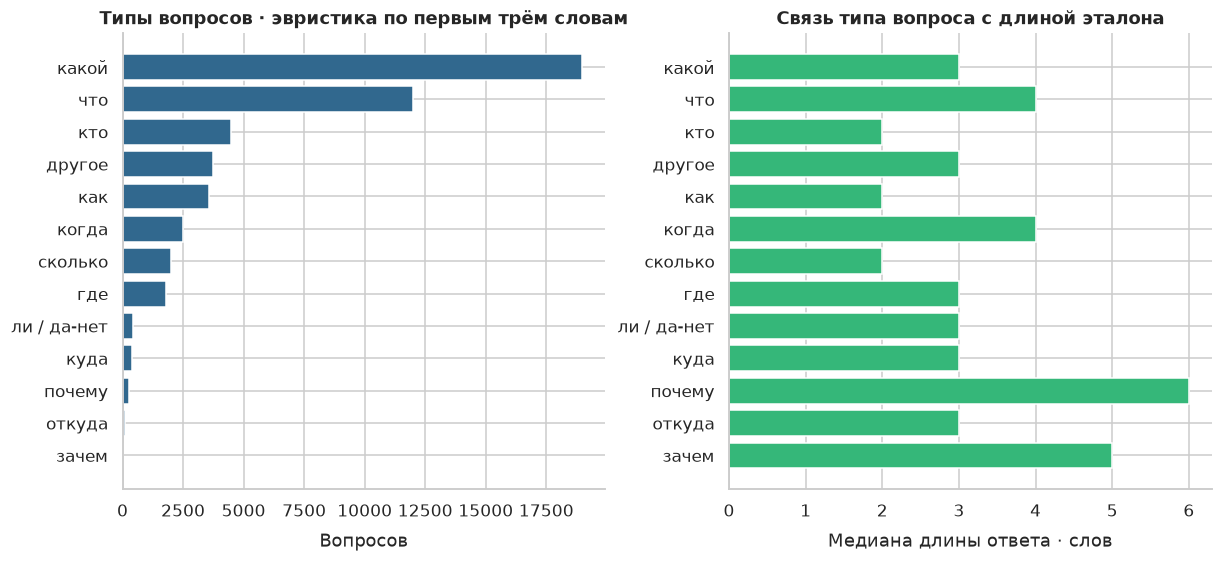

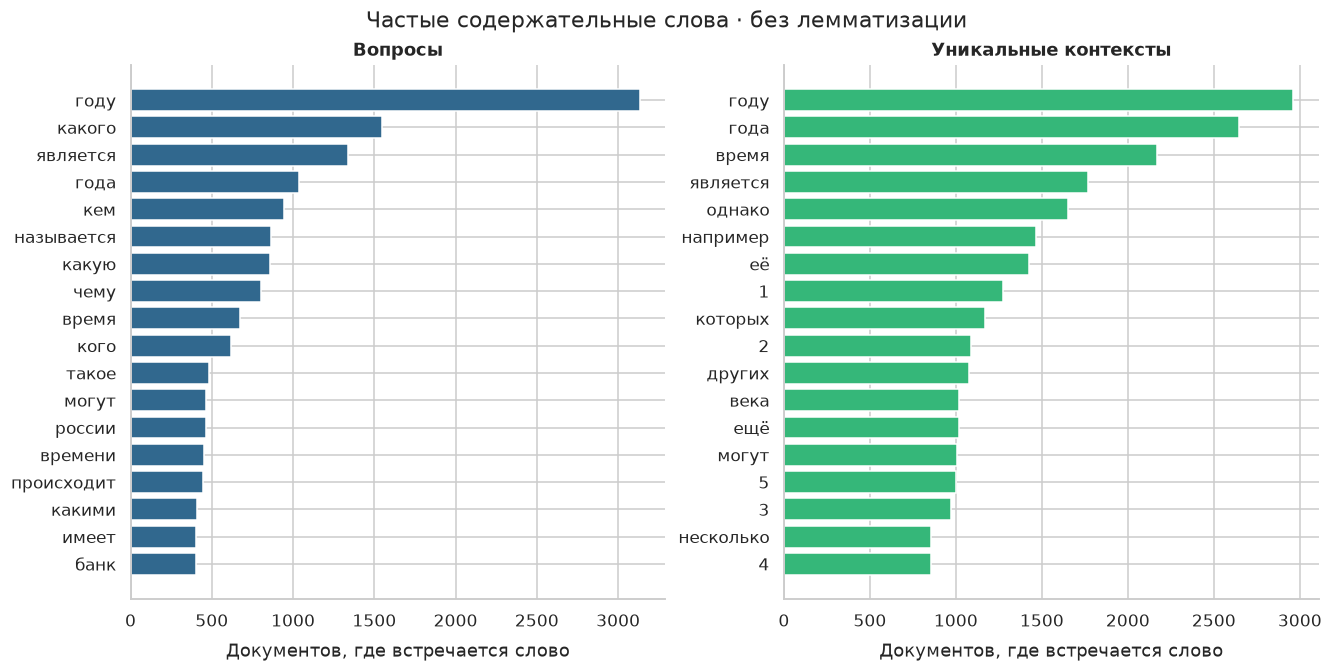

,answer_form,rows
0,текст / смешанный,49231
1,только числа и знаки,1123
2,да / нет,10


,flag,rows,fraction_of_labelled,action
0,no_final_question_mark,2690,0.053411,review_flag_not_automatic_deletion
1,question_at_most_two_words,41,0.000814,review_flag_not_automatic_deletion
2,wiki_citation_in_context,10633,0.211123,review_flag_not_automatic_deletion
3,context_reference_heuristic,1654,0.032841,review_flag_not_automatic_deletion
4,answer_ratio_at_least_09,1,0.000020,review_flag_not_automatic_deletion


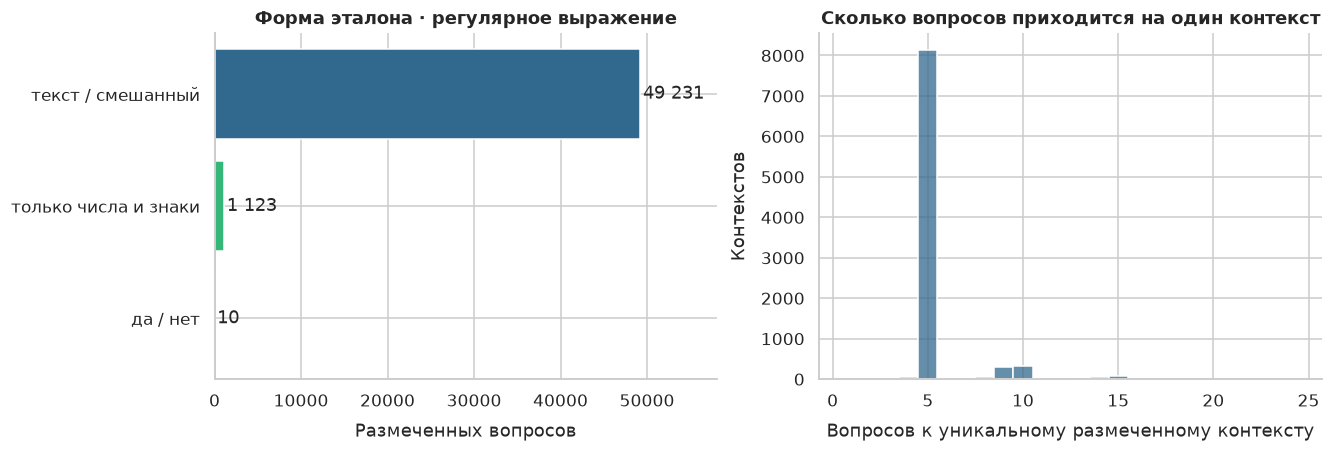

In [8]:
display(table("question_types"))
show_plot(plots.question_types(qa))
show_plot(plots.frequent_terms())
display(table("answer_forms"))
display(table("text_review_flags"))
show_plot(plots.answer_forms_and_question_counts())

Короткий запрос или отсутствие «?» сами по себе не означают ошибку.
Больше всего вопросов «какой» и «что». Ответы на «почему» в медиане длиннее,
чем на «кто»; при дальнейшем разборе ошибок эти группы стоит сравнивать отдельно.
Число вопросов на один абзац различается: при будущей оценке это нужно учитывать,
иначе тексты с большим числом вопросов получат больший вес.

In [9]:
display(table("source_distribution_shift"))
display(table("repeated_question_summary").head(10))

,feature,compared_to_train,train_median,other_median,ks_distance
0,q_words,validation,8.0,8.0,0.007144
1,q_words,test,8.0,8.0,0.005033
2,c_words,validation,91.0,90.5,0.008911
3,c_words,test,91.0,90.0,0.009500
4,c_e5_tokens,validation,180.0,179.0,0.008449
5,c_e5_tokens,test,180.0,180.0,0.013650
6,q_context_coverage,validation,0.8,0.8,0.011002
7,q_context_coverage,test,0.8,0.8,0.003372


,question_normalized,rows,contexts,distinct_answer_strings
0,"в каком году был получен первый патент на фотоаппарат, пригодный для моментальной фотографии?",2,1,2
1,в каком году железная дорога долины стубай начала использовать переменный ток?,2,1,2
2,где находится штаб-квартира банка?,2,2,2
3,для чего используется эпидемиология?,2,1,2
4,за счет чего клетки гиподермы начинают выделять новую кутикулу?,2,1,1
5,как изменяется имя существительное в чешском языке?,2,1,2
6,как изначально расшифровывалось dvd ?,2,1,2
7,"как называется процесс при котором эволюция одного вида вызывает эволюцию у другого вида, а...",2,1,2
8,"как называют озу, которое не надо регенерировать?",2,1,2
9,какие банки относились к банкам президентств ?,2,1,2


KS-distance показывает различие распределений длин между выборками.
Повторяющиеся вопросы с разными ответами оставлены для отдельного просмотра:
правильный ответ может зависеть от контекста.

## 8. Корреляции и парные распределения

Используем Spearman для длин и долей. Числовые ID и константный `score`
исключены. Вместо корреляции с текстовым ответом рассматриваем его длину и позицию.
Pairplot построен по 1 500 строкам с seed=42; для длин взят `log1p`.

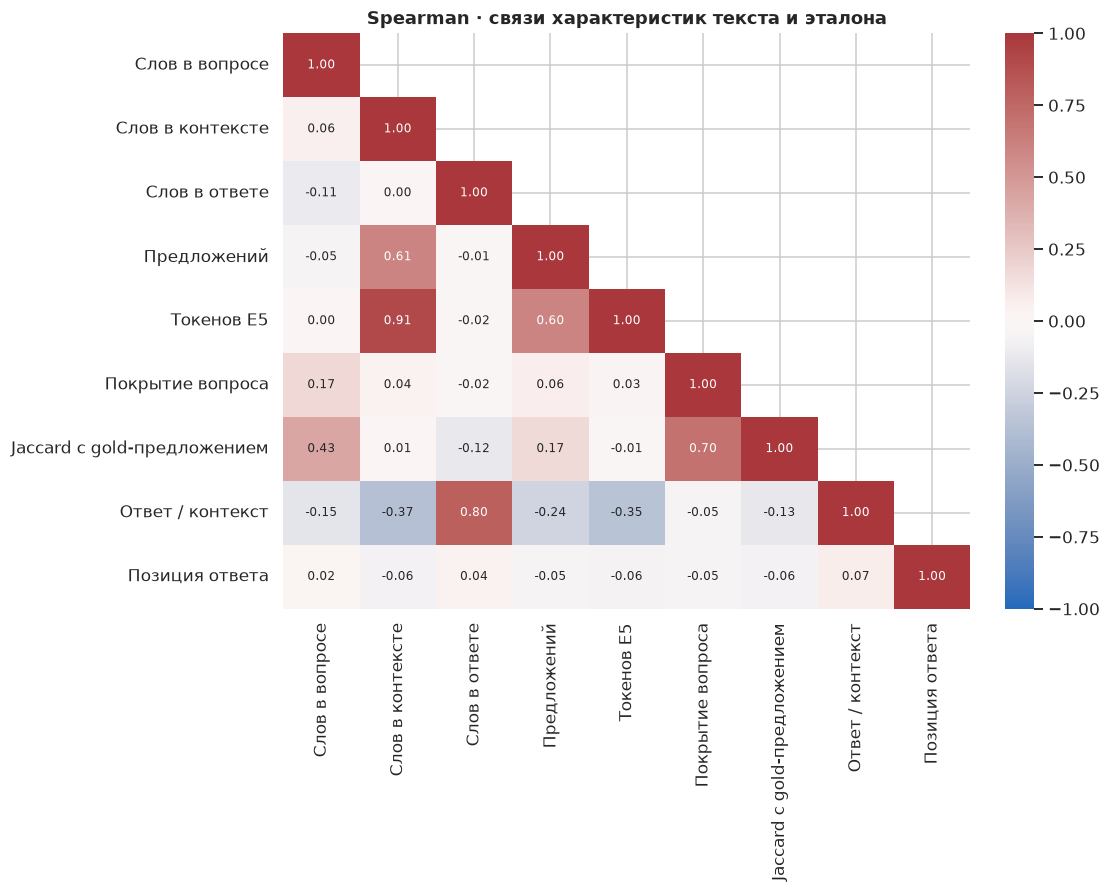

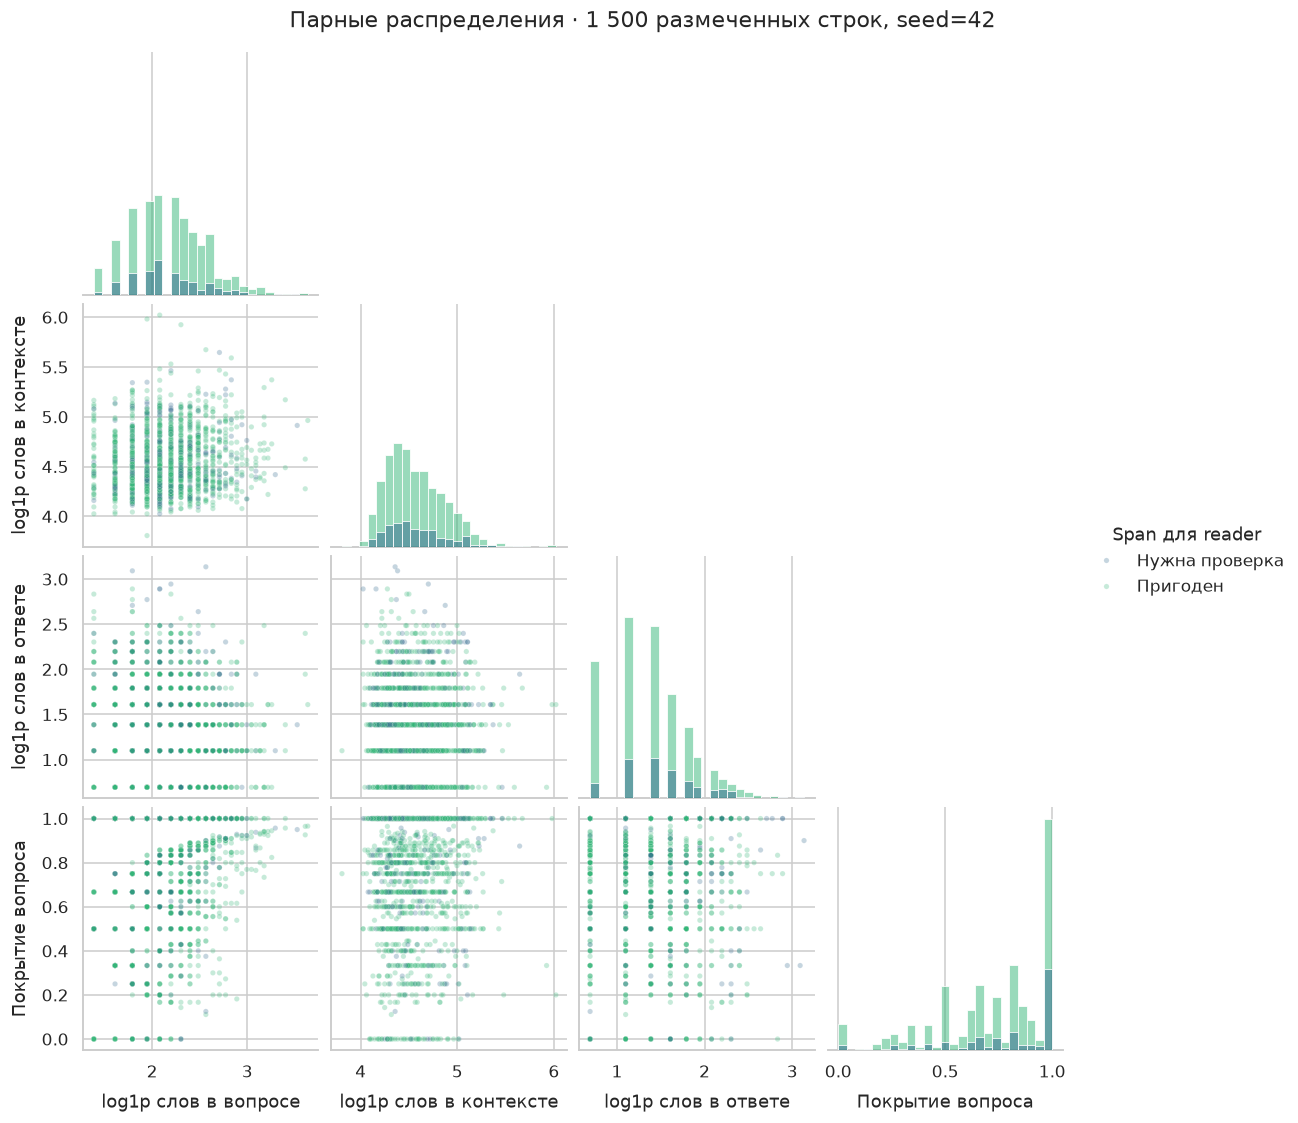

Связь длины контекста с длиной ответа слабая: Spearman = **0.001**. Длинный абзац не обязательно требует длинного ответа.

In [10]:
show_plot(plots.correlations(qa))
show_plot(plots.pairplot(qa))
corr = pd.read_csv(TABLES / "spearman_correlations.csv", index_col=0)
display(
    Markdown(
        f"Связь длины контекста с длиной ответа слабая: "
        f"Spearman = **{corr.loc['c_words', 'a_words']:.3f}**. "
        "Длинный абзац не обязательно требует длинного ответа."
    )
)

## 9. Дубли и пересечения выборок

Сравним ID, тексты и вопросы между исходными train, validation и test.

,left_split,right_split,key,shared_unique,left_rows_affected,right_rows_affected,right_fraction
0,train,validation,id,0,0,0,0.000000
1,train,validation,context_hash,3971,18396,5036,1.000000
2,train,validation,context_normalized_hash,3971,18401,5036,1.000000
3,train,validation,question_normalized,6,6,6,0.001191
4,train,validation,pair_hash,1,1,1,0.000199
5,train,test,id,11,11,11,0.000460
6,train,test,context_hash,14,59,68,0.002841
7,train,test,context_normalized_hash,14,59,68,0.002841
8,train,test,question_normalized,12,12,12,0.000501
9,train,test,pair_hash,1,1,1,0.000042


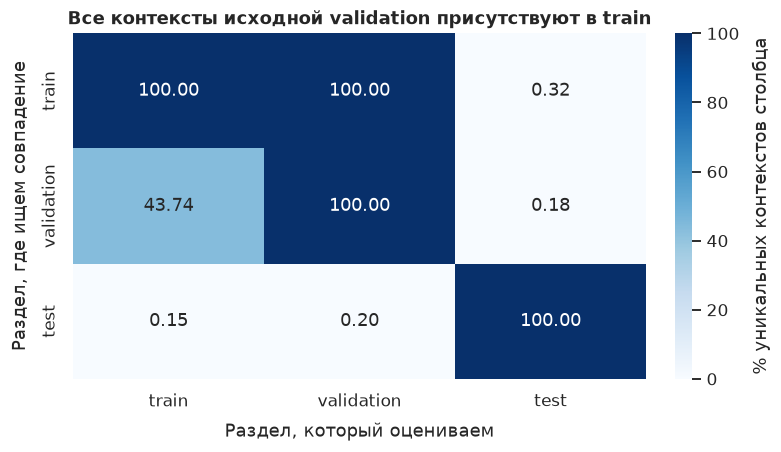

,row_key,id,split,question
0,train:1608,25348,train,Кто готов разрешить крупным микрофинансовым компаниям трансформироваться в банки с ограниче...
1,train:1657,63425,train,Что является отличительной чертой деления прокариотических клеток?
2,train:9143,46174,train,Чем отличается короткометражное кино от полнометражного?
3,train:14951,30719,train,Что такое сердце?
4,train:16504,48634,train,С какой целью
5,train:17750,32838,train,Чем обеспечивалась денежная эмиссия?
6,train:20158,36033,train,Какие организмы являются одноклеточными?
7,train:22151,5065,train,Для чего используется пересказывательное наклонение?
8,train:29306,25897,train,Какая гендерная система господствует в современном мире?
9,train:36427,27833,train,Из чего состоят облака?


queries                       74300
corpus_rows                   17474
unique_exact_contexts         13489
unique_normalized_contexts    13487
qrels                         74300
qrels_score_values              [1]
unmapped_qa_rows                  0
ambiguous_identity_rows           6
source_id_equals_query_id         1
Name: Сопоставление источников, dtype: object

In [11]:
display(table("split_overlap"))
show_plot(plots.source_overlap(qa))
display(table("repeated_original_ids").head(12))
display(pd.Series(summary["join_audit"], name="Сопоставление источников"))

Все контексты исходной validation уже встречаются в train. На таком разбиении
можно проверять новые вопросы к знакомой базе, но не перенос на новые документы.

QA ID и retrieval ID различаются, поэтому версии соединены по вопросу и контексту
внутри выборки. Для повторяющихся пар сохранён флаг `mapping_unique=False`.
Для одинаковых текстов введён `canonical_id`: он позволит не штрафовать будущий
поиск за возвращение копии правильного документа под другим ID.

## 10. Разбиение для проекта

Почти одинаковые тексты найдены по символьному TF-IDF: 4–5-граммы, до 40 тыс.
признаков, ближайший сосед каждого текста. Пары с cosine ≥0.90 сохранены для
просмотра, с cosine ≥0.97 объединены в одну группу разбиения. Это проверка
дублей; поисковый бейзлайн будет строиться отдельно по словам.

In [12]:
display(table("near_duplicate_candidates").sort_values("char_cosine", ascending=False).head(10))
display(table("project_split_summary"))
display(table("project_split_overlap"))

,left_id,right_id,char_cosine
36,7510,8594,1.000000
23,4777,8251,1.000000
44,14952,15827,0.999981
37,8288,17163,0.999501
3,437,5458,0.999047
40,14157,14161,0.999021
25,4870,8379,0.998956
38,13265,17452,0.998882
1,300,5932,0.998803
31,6094,8746,0.998564


,project_split,rows,contexts,groups,reader_eligible
0,test,5009,908,906,4067
1,train,40347,7258,7246,32892
2,validation,5008,911,906,4102


,left_split,right_split,key,shared_unique
0,train,validation,context_normalized_hash,0
1,train,validation,question_normalized,0
2,train,validation,split_group,0
3,train,test,context_normalized_hash,0
4,train,test,question_normalized,0
5,train,test,split_group,0
6,validation,test,context_normalized_hash,0
7,validation,test,question_normalized,0
8,validation,test,split_group,0


Размеченные строки разделены примерно в пропорции 80/10/10, seed=42.
Одинаковые нормализованные тексты, повторные вопросы и найденные почти дубли
остаются в одной выборке. Исходный test без ответов хранится отдельно.
Таблица соответствия — `data/processed/split_assignments.parquet`.

Разделение сделано по группам фрагментов, а не по статьям: ID исходных статей
неизвестны. Проектный test оставляем для итоговой оценки.

## 11. Что происходит с ответом при обрезке текста

Для этой проверки взят токенизатор `intfloat/multilingual-e5-small`:
E5 — компактная мультиязычная модель поиска, которую можно сравнить с
лексическим поиском на следующих этапах. Сейчас измеряем только длины
текстов в её токенах. Лимит модели — 512 токенов, включая префикс
`query:` / `passage:` и специальные токены ([карточка модели](https://huggingface.co/intfloat/multilingual-e5-small)).
Это пример ограничения для будущего нейросетевого этапа; веса E5 не загружаются.
Первый бейзлайн TF-IDF использует слова и не зависит от этого токенизатора.

Сравниваем сохранность целого ответа при обрезке начала текста и при нарезке
на окна. В первом случае бюджет включает префикс и спецтокены, во втором —
только содержимое окна. Сохранность ответа ещё не означает, что поиск найдёт окно.

count    13487.000000
mean       197.551346
std         69.603644
min         72.000000
50%        180.000000
90%        285.000000
95%        321.000000
99%        417.000000
max       2159.000000
Name: c_e5_tokens, dtype: float64

,method,content_window,overlap,evaluated,answer_retained_fraction
0,prefix_truncation,128,0,41061,0.757605
1,prefix_truncation,256,0,41061,0.982441
2,prefix_truncation,512,0,41061,0.999537
3,all_token_windows,128,0,41061,0.973259
4,all_token_windows,128,32,41061,0.999854
5,all_token_windows,256,0,41061,0.997930
6,all_token_windows,256,32,41061,0.999951


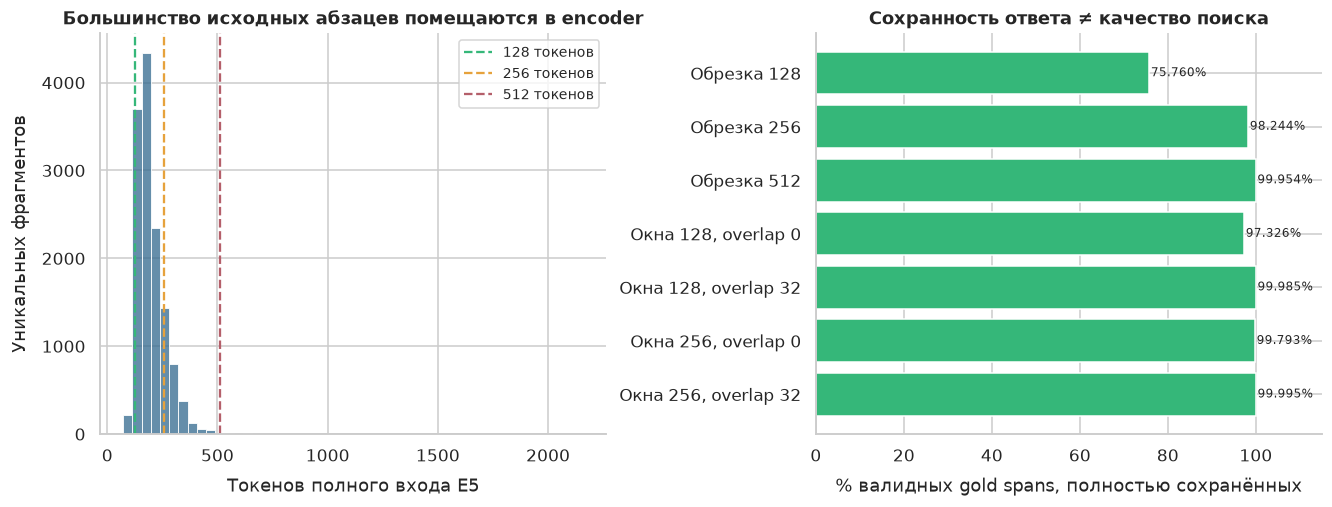

In [13]:
display(
    corpus.drop_duplicates("canonical_id").c_e5_tokens.describe(percentiles=[0.5, 0.9, 0.95, 0.99])
)
display(table("chunking_coverage"))
show_plot(plots.token_budgets(corpus))

Для первого бейзлайна оставим исходные абзацы целиком. Нарезку длинных текстов
и перекрытие окон проверим позже, когда появится ограничение нейросетевой модели.

## 12. Общие слова и положение ответа

Покрытие вопроса — доля его уникальных содержательных слов, встречающихся
в контексте. Jaccard с предложением ответа рассчитан по эталонной позиции
с помощью Razdel. Такой признак доступен только для анализа размеченных данных.

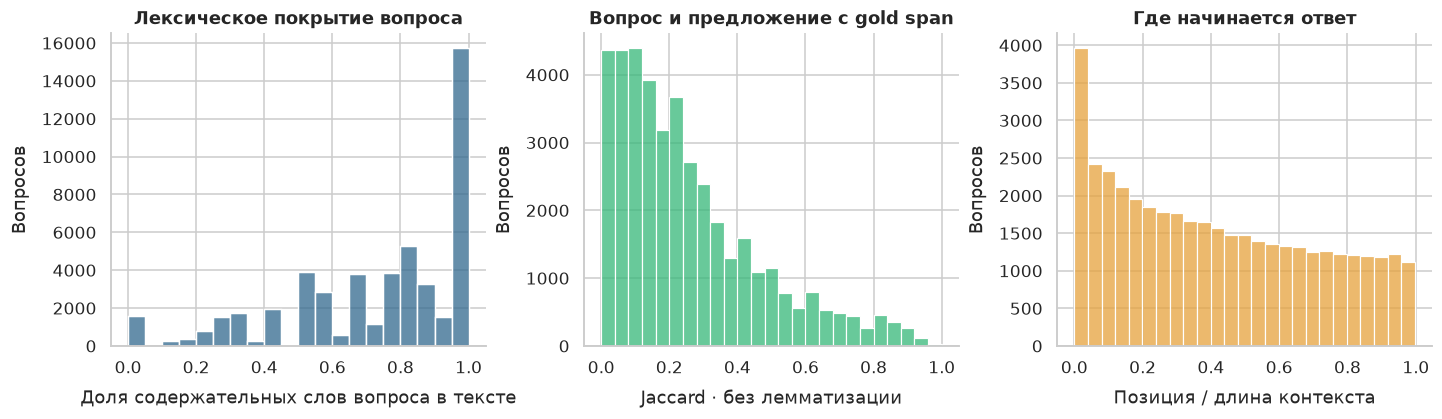

,count,mean,std,min,25%,50%,75%,max
q_context_coverage,50364.0,0.727136,0.271351,0.0,0.560764,0.800000,1.000000,1.000000
q_context_jaccard,50364.0,0.073314,0.055872,0.0,0.036585,0.061404,0.095745,0.959184
q_answer_sentence_jaccard,41061.0,0.253958,0.212954,0.0,0.092593,0.200000,0.357143,1.000000
a_position_relative,41061.0,0.414243,0.295877,0.0,0.149270,0.374364,0.660819,0.997126


Медианное покрытие вопроса словами контекста — **80%**. Это повод начать с TF-IDF и проверить качество лексического поиска на следующем чекпойнте.

In [14]:
show_plot(plots.lexical_and_position(qa))
display(
    labelled[
        [
            "q_context_coverage",
            "q_context_jaccard",
            "q_answer_sentence_jaccard",
            "a_position_relative",
        ]
    ]
    .describe()
    .T
)
display(
    Markdown(
        f"Медианное покрытие вопроса словами контекста — "
        f"**{labelled.q_context_coverage.median():.0%}**. "
        "Это повод начать с TF-IDF и проверить качество лексического поиска "
        "на следующем чекпойнте."
    )
)

## 13. Дальнейшие шаги

- В чекпойнте 3 построить TF-IDF по словам с косинусной близостью. Индексировать
  уникальные тексты корпуса; вопросы и эталоны использовать для оценки.
- Подбирать настройки на проектной validation. Test использовать в конце.
- Затем сравнить TF-IDF с BM25 и нейросетевым поиском на том же корпусе и разбиении.
- При оценке ответов отдельно проверять смысл: единственный короткий эталон
  может не учитывать другие правильные формулировки.

SberQuAD подходит для учебного поиска и коротких ответов по Wikipedia.
Для применения к рабочим документам понадобятся свои тексты и вопросы,
включая вопросы, ответа на которые в базе нет.

## Материалы

- [Выводы](../reports/eda_findings.md) и [словарь данных](../reports/data_dictionary.md).
- [Efimov et al., SberQuAD: Description and Analysis](https://arxiv.org/abs/1912.09723).
  Из статьи взяты идеи проверок пересечения слов и качества эталонов;
  числа в ноутбуке посчитаны для закреплённой версии данных.
- [RusBEIR](https://github.com/kaengreg/rusBEIR) — источник retrieval-версии.